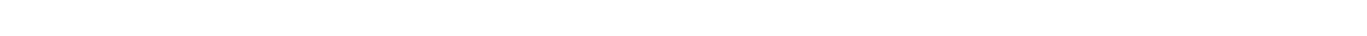

In [ ]:
import marimo as mo

# NB 2.01: Baseline, untuned Qwen2.5-1.5B-Instruct on the VNeST exercise task

| | |
|---|---|
| **Experiment(s)** | `b1`: untuned baseline (RESEARCH_LOG §3 step 2) |
| **Paper / report** | Results Summary §6.1 (test verbs), baseline rows |
| **Env** | Marimo machine with an RTX 6000; the kernel's torch + transformers (installed only if absent), `xgrammar` for schema-constrained decoding |
| **Inputs** | HF dataset `emmilly/vnest-exercise-llm-outputs`: `data/v1/{validation,test}.jsonl` + `data/v1/SHA256SUMS` (checksums verified). Model `Qwen/Qwen2.5-1.5B-Instruct` from the Hub |
| **Outputs** | Same HF repo: `runs/b1-qwen25-1.5b-instruct-untuned/` (config, raw generations, resources, `_done/` markers), `preds/b1__2.01__<run>__<split>__<prompt>-<decoding>.csv` (outputs + scores), `tables/b1__2.01__summary.csv`, `tables/b1__2.01__per-verb.csv`. W&B `team-me-and-me/vnest-exercise-llm`, run id = run name |
| **What it measures** | For every validation/test exercise: 2 prompts (`long` = the app's prompt, `short` = `VNeST exercise for the verb "x".`) × 2 decodings (`schema` = JSON-schema constrained like the app, `free` = unconstrained). Scored with the project's one scorer (`vnest_common.score_output`, a port of the app's `Scenario.fromModel`): acceptance, copying the example, generic "who", who is a person, answers/distractors against known valid ones. **All scores are automatic; none is a therapist judgement.** |
| **Decoding** | Greedy (deterministic), max 320 new tokens (app: temperature 0.3, 320 tokens). Model in bf16 on GPU, so not the phone's 4-bit model |
| **Keys** | KEYS cell below (HF token of `emmilly` with write access, W&B API key), or env vars `HF_TOKEN` / `WANDB_API_KEY` |
| **How to run** | Interactive: open in Marimo, run all. Unattended: `mkdir -p ~/vnest/logs && nohup python 01_baseline_qwen25_untuned.py > ~/vnest/logs/2.01_baseline_qwen.log 2>&1 &` then `tail -f ~/vnest/logs/2.01_baseline_qwen.log` |
| **Memory / batch** | ~4 GB GPU for the model; `BATCH_SIZE` 16 halves itself on out-of-memory |
| **Resume after a crash** | Each of the 8 parts (split × prompt × decoding) is uploaded as soon as it finishes; a re-run reads finished parts back from HF and only generates the rest. Scoring re-runs automatically if the raw outputs changed (fingerprint) |
| **Runtime** | Roughly 10–25 min on an RTX 6000 (520 generations) |
| **Forked from** | none (first evaluation notebook) |

**Test = 5 verbs (cook, drive, paint, plant, wash), 85 exercises.** Validation = chop, eat, lift, play, smell (45). Every number below is over 5 verbs; confidence intervals resample verbs.

In [ ]:
# ══════════════ KEYS: paste yours between the quotes (only if not already set as environment variables) ══════════════
HF_TOKEN = "hf_YOUR_TOKEN_HERE"          # ← HF token of account emmilly, WRITE access (huggingface.co/settings/tokens)
WANDB_API_KEY = "wandb_YOUR_KEY_HERE"    # ← W&B API key (wandb.ai/authorize)
# ════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
# Exported .ipynb files keep whatever is pasted above: put the placeholders back before sharing a file.
if "YOUR_TOKEN" in HF_TOKEN:
    HF_TOKEN = os.environ.get("HF_TOKEN", "")
if "YOUR_KEY" in WANDB_API_KEY:
    WANDB_API_KEY = os.environ.get("WANDB_API_KEY", "")
os.environ["HF_TOKEN"] = HF_TOKEN
if WANDB_API_KEY:
    os.environ["WANDB_API_KEY"] = WANDB_API_KEY
print(f"HF_TOKEN set: {bool(HF_TOKEN)} | WANDB_API_KEY set: {bool(WANDB_API_KEY)}")

HF_TOKEN set: True | WANDB_API_KEY set: True


In [ ]:
import gc
import hashlib
import json
import os
import sys
import time
from pathlib import Path

In [ ]:
# ───────────────────────────── config: everything tunable lives here ─────────────────────────────
NOTEBOOK = "2.01"
EXP_ID = "b1"
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
MODEL_SHORT = "qwen25-1.5b-instruct"
VARIANT = "untuned"
RUN_NAME = f"{EXP_ID}-{MODEL_SHORT}-{VARIANT}"   # checked by wc.run_name below

SPLITS = ["validation", "test"]          # never select anything on test
PROMPT_STYLES = ["long", "short"]        # long = the app's prompt; short = what a fine-tuned model may use
DECODINGS = ["schema", "free"]           # schema = JSON-schema constrained like the app (xgrammar); free = none
MAX_NEW_TOKENS = 320                     # same as the app
BATCH_SIZE = 16                          # halves automatically on GPU out-of-memory
TORCH_DTYPE = "bfloat16"
LIMIT_PER_SPLIT = None                   # e.g. 5 for a quick smoke test (uses a deterministic md5 subset)

STAGES = {"generate": True, "score": True, "summary": True}
FORCE = set()                            # e.g. {"score"} to redo a finished stage

WORK_ROOT = Path(os.environ.get("VNEST_WORK", str(Path.home() / "vnest")))
WORK_DIR = WORK_ROOT / "runs" / RUN_NAME
WORK_DIR.mkdir(parents=True, exist_ok=True)
CFG = dict(notebook=NOTEBOOK, exp_id=EXP_ID, model_id=MODEL_ID, variant=VARIANT, run_name=RUN_NAME,
           splits=SPLITS, prompt_styles=PROMPT_STYLES, decodings=DECODINGS, max_new_tokens=MAX_NEW_TOKENS,
           batch_size=BATCH_SIZE, torch_dtype=TORCH_DTYPE, do_sample=False, limit_per_split=LIMIT_PER_SPLIT)
print(f"run {RUN_NAME} | work dir {WORK_DIR}")

run b1-qwen25-1.5b-instruct-untuned | work dir /home/marimo/vnest/runs/b1-qwen25-1.5b-instruct-untuned


In [ ]:
# ───────────── shared module (vnest_common), embedded; regenerate with tools/make_standalone.py ─────────────
import base64 as _b64
import importlib as _il
import subprocess as _sp
_EMBED_VERSION = "1.0.0"
_EMBED_B64 = "..."  # >>> vnest_common (do not edit: tools/make_standalone.py)
for _pkg in ("huggingface_hub", "pandas", "numpy"):
    try:
        _il.import_module(_pkg)
    except ImportError:
        _sp.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)
_dir = Path(WORK_ROOT) / "common"
_dir.mkdir(parents=True, exist_ok=True)
(_dir / "vnest_common.py").write_bytes(_b64.b64decode(_EMBED_B64))
if str(_dir) not in sys.path:
    sys.path.insert(0, str(_dir))
import vnest_common as wc
wc = _il.reload(wc)
assert wc.VERSION == _EMBED_VERSION, (wc.VERSION, _EMBED_VERSION)
_acct = wc.whoami()
print(f"vnest_common {wc.VERSION} | HF token account: {_acct}")
if _acct != wc.HF_USER:
    print(f"WARNING: token belongs to {_acct!r}, not {wc.HF_USER!r}: uploads to {wc.OUTPUTS_REPO} will fail (403)")

vnest_common 1.0.0 | HF token account: emmilly


In [ ]:
# ───────────── libraries (env vars before CUDA initialises; install only if absent, never upgrade) ─────────────
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import importlib as _il2
import subprocess as _sp2
for _pkg, _mod in (("transformers", "transformers"), ("accelerate", "accelerate"), ("xgrammar", "xgrammar"),
                   ("wandb", "wandb")):
    try:
        _il2.import_module(_mod)
    except ImportError:
        print(f"installing {_pkg}")
        _r = _sp2.run([sys.executable, "-m", "pip", "install", "-q", _pkg])
        if _r.returncode != 0:
            print(f"could not install {_pkg} (rc {_r.returncode})")
import pandas as pd
import torch
import transformers
try:
    import xgrammar as xgr
    import xgrammar.contrib.hf  # noqa: F401  (the transformers logits processor)
    XGR_ERROR = None
except Exception as _e:
    xgr, XGR_ERROR = None, f"{type(_e).__name__}: {_e}"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
import importlib.metadata as _md
VERSIONS = {"python": sys.version.split()[0], "torch": torch.__version__, "transformers": transformers.__version__,
            "xgrammar": _md.version("xgrammar") if xgr else None, "pandas": pd.__version__,
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu"}
print(VERSIONS)
if XGR_ERROR:
    print(f"WARNING: xgrammar unavailable ({XGR_ERROR}): the 'schema' parts will be skipped and reported as such")
if DEVICE != "cuda":
    print("WARNING: no GPU found: generation will be very slow")

installing accelerate



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


installing xgrammar



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


{'python': '3.13.11', 'torch': '2.11.0+cu130', 'transformers': '5.14.1', 'xgrammar': '0.2.9', 'pandas': '3.0.3', 'gpu': 'NVIDIA RTX PRO 6000 Blackwell Server Edition'}


In [ ]:
# ───────────── data: download data/v1, verify checksums, enforce the split rule ─────────────
with mo.status.spinner(title="Downloading dataset v1 from HF"):
    _sums_p = wc.hf_download(f"data/{wc.DATA_VERSION}/SHA256SUMS", WORK_DIR)
    assert _sums_p, f"data/{wc.DATA_VERSION}/SHA256SUMS missing in {wc.OUTPUTS_REPO}"
    EXPECTED_SHA = dict(reversed(_l.split()) for _l in _sums_p.read_text().splitlines() if _l.strip())
    _rows, DATA_SHA = {}, {}
    for _split in ("train", "validation", "test"):
        _p = wc.hf_download(wc.data_path(_split), WORK_DIR)
        DATA_SHA[_split] = wc.sha256_file(_p)
        assert DATA_SHA[_split] == EXPECTED_SHA[f"{_split}.jsonl"], f"{_split}.jsonl checksum mismatch"
        _rows[_split] = wc.load_jsonl(_p)
_ov = wc.check_split_verbs(_rows["train"], _rows["validation"], _rows["test"])
print(f"verb overlap train&val={_ov['train&val']} train&test={_ov['train&test']} val&test={_ov['val&test']} (must all be [])")
assert not (_ov["train&val"] or _ov["train&test"] or _ov["val&test"]), "split rule broken"
assert tuple(_ov["test_verbs"]) == wc.TEST_VERBS, _ov["test_verbs"]

ITEMS = {}
for _split in SPLITS:
    _its = wc.items_from_split(_rows[_split], _split)
    if LIMIT_PER_SPLIT:
        _keep = set(wc.subset_md5([i["idx"] for i in _its], LIMIT_PER_SPLIT, salt=_split))
        _its = [i for i in _its if i["idx"] in _keep]
    ITEMS[_split] = _its
REFS = wc.known_valid([i for _s in ("validation", "test") for i in wc.items_from_split(_rows[_s], _s)])
print("checksums OK |", {k: len(v) for k, v in ITEMS.items()}, "items | DATA_SHA",
      {k: v[:10] for k, v in DATA_SHA.items()})

verb overlap train&val=[] train&test=[] val&test=[] (must all be [])
checksums OK | {'validation': 45, 'test': 85} items | DATA_SHA {'train': 'f18824fe04', 'validation': 'e982f94ae1', 'test': '119fcaa2a5'}


In [ ]:
# ───────────── bookkeeping: run lock, stages, W&B, config on HF ─────────────
_parts = wc.parse_run_name(RUN_NAME)
assert wc.run_name(_parts["exp"], _parts["model"], _parts["variant"]) == RUN_NAME and _parts["exp"] == EXP_ID, RUN_NAME
LOCK = wc.claim_run(WORK_DIR)
wc.ensure_outputs_repo(HF_TOKEN)
stages = wc.Stages(RUN_NAME, STAGES, FORCE, WORK_DIR, HF_TOKEN)
RUN_CONFIG = {**CFG, "data_version": wc.DATA_VERSION, "data_sha256": DATA_SHA, "module_version": wc.VERSION,
              "versions": VERSIONS, "git_commit": "unknown", "scoring": "vnest_common.score_output (automatic only)"}
wb, log_fn = wc.wandb_init(RUN_NAME, "eval", [f"exp:{EXP_ID}", f"nb:{NOTEBOOK}", "model:qwen2.5-1.5b-instruct",
                                              "variant:untuned", "baseline"], RUN_CONFIG)
wc.put_json(RUN_CONFIG, f"{wc.run_dir(RUN_NAME)}/config.json", WORK_DIR, f"{RUN_NAME}: config", HF_TOKEN)
RESOURCES_CSV = WORK_DIR / "resources.csv"
print(f"lock {LOCK} | W&B {'on' if wb else 'off'} | config uploaded")

wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: enamugan (team-me-and-me) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run b1-qwen25-1.5b-instruct-untuned
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /marimo/wandb/run-20261110_140735-b1-qwen25-1.5b-instruct-untuned
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run b1-qwen25-1.5b-instruct-untuned
wandb: ⭐️ View project at https://wandb.ai/team-me-and-me/vnest-exercise-llm
wandb: 🚀 View run at https://wandb.ai/team-me-and-me/vnest-exercise-llm/runs/b1-qwen25-1.5b-instruct-untuned


lock /home/marimo/vnest/runs/b1-qwen25-1.5b-instruct-untuned/run.lock | W&B on | config uploaded


[hf] download runs/b1-qwen25-1.5b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af32529-597e04507939748574ba1f24;21f8025c-1e82-47af-819a-6642a621861d)

Entry Not -> retry in 5s
[hf] download runs/b1-qwen25-1.5b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af3252e-46438f2a1ac0fc0c7858ffe0;825d19e6-b3b4-4798-82cd-a6eece622431)

Entry Not -> retry in 10s
[hf] download runs/b1-qwen25-1.5b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af32538-0b9ad63e378b5e4a0d6b3fdb;21a98e34-27bb-4bcc-9dd3-29043259fcaa)

Entry Not -> retry in 20s
[hf] download runs/b1-qwen25-1.5b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af3254c-5360810b5f6feef5187efde7;61ffc694-e1a4-4a80-8c43-c90a86b6edb4)

Entry Not -> retry in 40s
[hf] download runs/b1-qwen25-1.5b-instruct-untuned/_done/generate.json: 404 Client Error. (Request ID: Root=1-6af32574-723ba7314425cfef2344bb2e;5ff16f1e-c5d9-4f07-89

Loading weights: 100%|██████████| 338/338 [00:00<00:00, 3255.09it/s]


[resources] generate-validation-long-schema: ok | 0.0038 h | peak GPU 3.72 GB | 497.8 tok/s
[generate] validation/long-schema: 45 outputs, 0 empty, 19 distinct, mean 151 tokens
[resources] generate-validation-long-free: ok | 0.0028 h | peak GPU 3.72 GB | 657.3 tok/s
[generate] validation/long-free: 45 outputs, 0 empty, 19 distinct, mean 149 tokens
[resources] generate-validation-short-schema: ok | 0.0044 h | peak GPU 3.29 GB | 542.4 tok/s
[generate] validation/short-schema: 45 outputs, 0 empty, 20 distinct, mean 190 tokens
[resources] generate-validation-short-free: ok | 0.0022 h | peak GPU 3.23 GB | 493.6 tok/s
[generate] validation/short-free: 45 outputs, 0 empty, 18 distinct, mean 86 tokens
[hf] download runs/b1-qwen25-1.5b-instruct-untuned/raw/test__long-schema.csv: 404 Client Error. (Request ID: Root=1-6af32608-1b104ee35b6dca5d223cd226;8281f502-ec18-4cc4-8641-c0332ce88839)

Entry Not -> retry in 5s
[resources] generate-test-long-schema: ok | 0.0062 h | peak GPU 3.72 GB | 577.2 tok

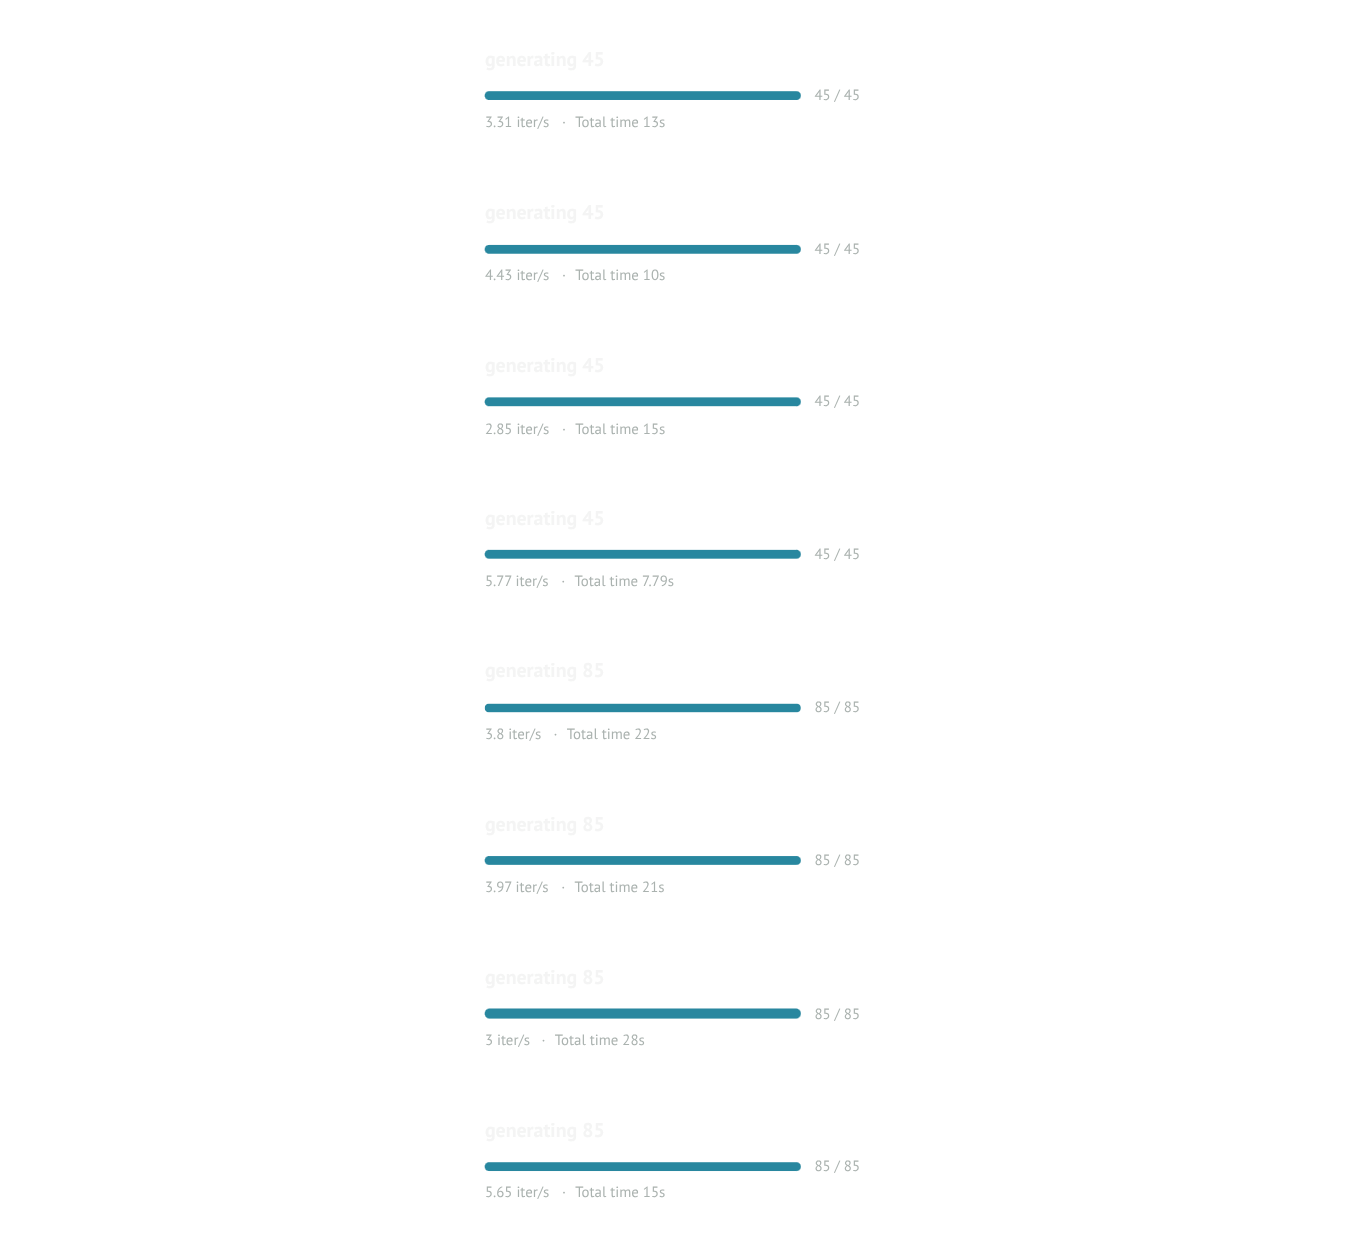

In [ ]:
# ───────────── stage: generate (8 parts, each saved to HF as soon as it finishes) ─────────────
PARTS = [(s, p, d) for s in ITEMS for p in PROMPT_STYLES for d in DECODINGS]

def _raw_path(split_, style_, dec_):
    return f"{wc.run_dir(RUN_NAME)}/raw/{split_}__{style_}-{dec_}.csv"

def _load_model():
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok_ = AutoTokenizer.from_pretrained(MODEL_ID, token=HF_TOKEN or None)
    tok_.padding_side = "left"  # decoder-only batching
    if tok_.pad_token is None:
        tok_.pad_token = tok_.eos_token
    try:
        model_ = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=getattr(torch, TORCH_DTYPE), token=HF_TOKEN or None)
    except TypeError:  # transformers < 4.56 calls it torch_dtype
        model_ = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=getattr(torch, TORCH_DTYPE), token=HF_TOKEN or None)
    model_.to(DEVICE).eval()
    return tok_, model_

def _grammar(tok_, model_):
    info_ = xgr.TokenizerInfo.from_huggingface(tok_, vocab_size=model_.config.vocab_size)
    return xgr.GrammarCompiler(info_).compile_json_schema(json.dumps(wc.SCENARIO_SCHEMA))

def _generate_batch(tok_, model_, prompts_, compiled_):
    msgs_ = [[{"role": "system", "content": wc.SYSTEM_PROMPT}, {"role": "user", "content": p_}] for p_ in prompts_]
    texts_ = [tok_.apply_chat_template(m_, tokenize=False, add_generation_prompt=True) for m_ in msgs_]
    enc_ = tok_(texts_, return_tensors="pt", padding=True).to(DEVICE)
    kw_ = dict(max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None, top_k=None,
               pad_token_id=tok_.pad_token_id)
    if compiled_ is not None:
        from transformers import LogitsProcessorList
        kw_["logits_processor"] = LogitsProcessorList([xgr.contrib.hf.LogitsProcessor(compiled_)])
    with torch.no_grad():
        out_ = model_.generate(**enc_, **kw_)
    gen_ = out_[:, enc_["input_ids"].shape[1]:]
    res_ = []
    for row_ in gen_:
        ids_ = [t_ for t_ in row_.tolist() if t_ != tok_.pad_token_id]
        res_.append((tok_.decode(ids_, skip_special_tokens=True), len(ids_)))
    return res_

def _run_part(tok_, model_, compiled_, items_, style_):
    rows_, bs_, i_ = [], BATCH_SIZE, 0
    bar_ = mo.status.progress_bar(total=len(items_), title=f"generating {len(items_)}", show_eta=True, show_rate=True)
    with bar_ as b_:
        while i_ < len(items_):
            chunk_ = items_[i_:i_ + bs_]
            prompts_ = [wc.prompt_for(style_, it_["verb"], it_["avoid"]) for it_ in chunk_]
            t0_ = time.time()
            try:
                outs_ = _generate_batch(tok_, model_, prompts_, compiled_)
            except torch.OutOfMemoryError:
                torch.cuda.empty_cache()
                if bs_ == 1:
                    raise
                bs_ = max(1, bs_ // 2)
                print(f"  out of memory: batch size -> {bs_}")
                continue
            dt_ = (time.time() - t0_) / len(chunk_)
            for it_, p_, (txt_, n_) in zip(chunk_, prompts_, outs_):
                rows_.append({"split": it_["split"], "idx": it_["idx"], "verb": it_["verb"],
                              "avoid": "|".join(it_["avoid"]), "prompt": p_, "output": txt_, "gen_tokens": n_,
                              "sec_per_item_batched": round(dt_, 3)})
            b_.update(increment=len(chunk_))
            i_ += len(chunk_)
    return pd.DataFrame(rows_)

RAW = {}
if stages.should_run("generate"):
    _tok = _model = _compiled = None
    for _split, _style, _dec in PARTS:
        _path = _raw_path(_split, _style, _dec)
        _local = wc.hf_download(_path, WORK_DIR) if "generate" not in stages.force else None
        if _local is not None:
            RAW[(_split, _style, _dec)] = wc.read_csv(_local)
            print(f"[generate] {_split}/{_style}-{_dec}: read back {len(RAW[(_split, _style, _dec)])} rows from HF")
            continue
        if _dec == "schema" and xgr is None:
            print(f"[generate] {_split}/{_style}-{_dec}: SKIPPED, xgrammar unavailable ({XGR_ERROR})")
            continue
        if _model is None:
            with mo.status.spinner(title=f"Loading {MODEL_ID}"):
                _tok, _model = _load_model()
        if _dec == "schema" and _compiled is None:
            _compiled = _grammar(_tok, _model)
        with wc.track_resources(f"generate-{_split}-{_style}-{_dec}", log_fn=log_fn, csv_path=RESOURCES_CSV,
                                n_items=len(ITEMS[_split])) as _rec:
            _df = _run_part(_tok, _model, _compiled if _dec == "schema" else None, ITEMS[_split], _style)
            _df["decoding"], _df["prompt_style"] = _dec, _style
            _rec["gen_tokens"] = int(_df["gen_tokens"].sum())
        # sanity before saving: right row count, not all empty
        assert len(_df) == len(ITEMS[_split]), (len(_df), len(ITEMS[_split]))
        _n_empty = int((_df["output"].astype(str).str.strip() == "").sum())
        print(f"[generate] {_split}/{_style}-{_dec}: {len(_df)} outputs, {_n_empty} empty, "
              f"{_df['output'].nunique()} distinct, mean {_df['gen_tokens'].mean():.0f} tokens")
        assert _n_empty < len(_df), "every output empty: something is wrong"
        _lp = WORK_DIR / _path
        _lp.parent.mkdir(parents=True, exist_ok=True)
        _df.to_csv(_lp, index=False)
        wc.hf_upload(_lp, _path, f"{RUN_NAME}: raw {_split}/{_style}-{_dec}", HF_TOKEN)
        RAW[(_split, _style, _dec)] = _df
    if RESOURCES_CSV.exists():
        wc.hf_upload(RESOURCES_CSV, f"{wc.run_dir(RUN_NAME)}/resources.csv", f"{RUN_NAME}: resources", HF_TOKEN)
    _missing = [f"{_s}/{_p}-{_d}" for _s, _p, _d in PARTS if (_s, _p, _d) not in RAW]
    if not _missing:
        stages.mark_done("generate", {"parts": [f"{_s}/{_p}-{_d}" for _s, _p, _d in PARTS],
                                      "rows": {f"{_s}/{_p}-{_d}": len(_v) for (_s, _p, _d), _v in RAW.items()}})
    else:
        print(f"[generate] NOT marked done; missing parts: {_missing}")
    del _model, _tok
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
else:
    for _split, _style, _dec in PARTS:
        _local = wc.hf_download(_raw_path(_split, _style, _dec), WORK_DIR)
        if _local is not None:
            RAW[(_split, _style, _dec)] = wc.read_csv(_local)
    print(f"[generate] read back {len(RAW)}/{len(PARTS)} parts from HF")

In [ ]:
# ───────────── stage: score (re-runs automatically if the raw outputs changed) ─────────────
def _fingerprint(raw_):
    h_ = hashlib.md5()
    for k_ in sorted(raw_):
        h_.update(str(k_).encode())
        h_.update(raw_[k_][["idx", "output"]].to_csv(index=False).encode())
    return h_.hexdigest()

FP = _fingerprint(RAW)
_marker = stages.marker("score")
_stale = bool(_marker) and _marker.get("raw_fingerprint") != FP
if _stale:
    print(f"[score] raw outputs changed since last scoring ({_marker.get('raw_fingerprint')} -> {FP}): re-scoring")
SCORED = {}
if _stale or stages.should_run("score"):
    for (_split, _style, _dec), _raw in RAW.items():
        _rows = [{"exp_id": EXP_ID, "notebook": NOTEBOOK, "run_name": RUN_NAME, **_r,
                  **wc.score_output(str(_r["output"]), _r["verb"], REFS[_r["verb"]])} for _r in _raw.to_dict("records")]
        _df = pd.DataFrame(_rows)
        _path = wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, f"{_style}-{_dec}")
        _lp = WORK_DIR / _path
        _lp.parent.mkdir(parents=True, exist_ok=True)
        _df.to_csv(_lp, index=False)
        wc.hf_upload(_lp, _path, f"{RUN_NAME}: scored {_split}/{_style}-{_dec}", HF_TOKEN)
        SCORED[(_split, _style, _dec)] = _df
        print(f"[score] {_split}/{_style}-{_dec}: accepted {_df['accepted'].mean():.0%}, "
              f"copies example {_df['copies_example'].mean():.0%}, generic who {_df['generic_who'].mean():.0%} -> {_path}")
    assert all(len(SCORED[_k]) == len(RAW[_k]) for _k in RAW)
    if SCORED:
        stages.mark_done("score", {"raw_fingerprint": FP, "parts": len(SCORED)})
else:
    for (_split, _style, _dec) in RAW:
        _local = wc.hf_download(wc.preds_path(EXP_ID, NOTEBOOK, RUN_NAME, _split, f"{_style}-{_dec}"), WORK_DIR)
        if _local is not None:
            SCORED[(_split, _style, _dec)] = wc.read_csv(_local)
    print(f"[score] read back {len(SCORED)} scored parts")

[score] validation/long-schema: accepted 98%, copies example 0%, generic who 27% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__validation__long-schema.csv
[score] validation/long-free: accepted 91%, copies example 0%, generic who 24% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__validation__long-free.csv
[score] validation/short-schema: accepted 2%, copies example 0%, generic who 7% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__validation__short-schema.csv
[score] validation/short-free: accepted 0%, copies example 0%, generic who 0% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__validation__short-free.csv
[score] test/long-schema: accepted 100%, copies example 0%, generic who 44% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__test__long-schema.csv
[score] test/long-free: accepted 73%, copies example 0%, generic who 44% -> preds/b1__2.01__b1-qwen25-1.5b-instruct-untuned__test__long-free.csv
[score] test/short-schema: accepted 2%, copies example 0%, generic wh

[summary] OK -> tables/b1__2.01__summary.csv, tables/b1__2.01__per-verb.csv


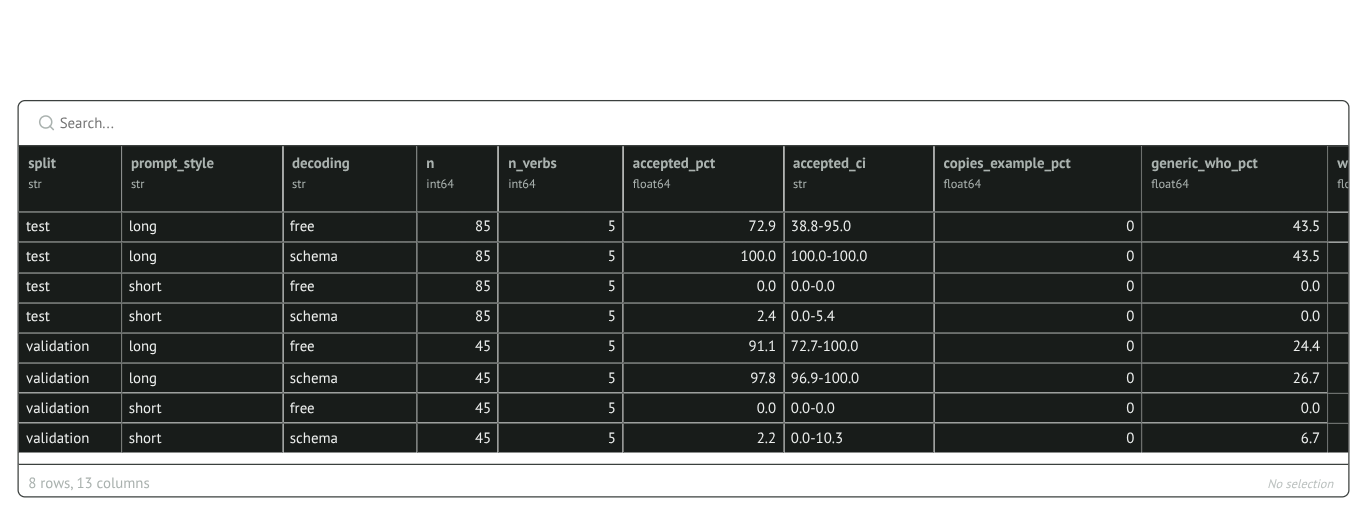

In [ ]:
# ───────────── stage: summary tables (per variant; per test verb) ─────────────
ALL = pd.concat(SCORED.values(), ignore_index=True) if SCORED else pd.DataFrame()
for _c in wc.METRICS:
    if _c in ALL:
        ALL[_c] = ALL[_c].astype(str).str.lower().isin(["true", "1"]) if ALL[_c].dtype == object else ALL[_c].astype(bool)
_sum_path = wc.table_path(EXP_ID, NOTEBOOK, "summary")
_verb_path = wc.table_path(EXP_ID, NOTEBOOK, "per-verb")
if ALL.empty:
    SUMMARY = PER_VERB = pd.DataFrame()
    print("[summary] nothing scored yet: no tables written")
else:
    # Always recomputed from the scored outputs (cheap), so the tables can never go stale.
    SUMMARY = wc.summarise(ALL, ["split", "prompt_style", "decoding"])
    SUMMARY.insert(0, "model", "Qwen2.5-1.5B-Instruct (untuned, bf16)")
    PER_VERB = wc.summarise(ALL[ALL["split"] == "test"], ["prompt_style", "decoding", "verb"])
    for _df, _path in ((SUMMARY, _sum_path), (PER_VERB, _verb_path)):
        _lp = WORK_DIR / _path
        _lp.parent.mkdir(parents=True, exist_ok=True)
        _df.to_csv(_lp, index=False)
        wc.hf_upload(_lp, _path, f"{RUN_NAME}: {_path}", HF_TOKEN)
    if log_fn:
        for _r in SUMMARY.to_dict("records"):
            _pre = f"{_r['split']}/{_r['prompt_style']}-{_r['decoding']}"
            log_fn({f"{_pre}/{m}_pct": _r[f"{m}_pct"] for m in wc.METRICS} | {f"{_pre}/n": _r["n"]})
    stages.mark_done("summary", {"tables": [_sum_path, _verb_path], "rows": len(SUMMARY)})
    print(f"[summary] OK -> {_sum_path}, {_verb_path}")
_show = ["split", "prompt_style", "decoding", "n", "n_verbs", "accepted_pct", "accepted_ci", "copies_example_pct",
         "generic_who_pct", "who_is_person_pct", "what_known_valid_pct", "any_bad_distractor_pct", "mean_gen_tokens"]
mo.vstack([mo.md("### Results (automatic scores; test = 5 verbs)"),
           mo.ui.table(SUMMARY[[c for c in _show if c in SUMMARY]] if not SUMMARY.empty else SUMMARY, selection=None)])

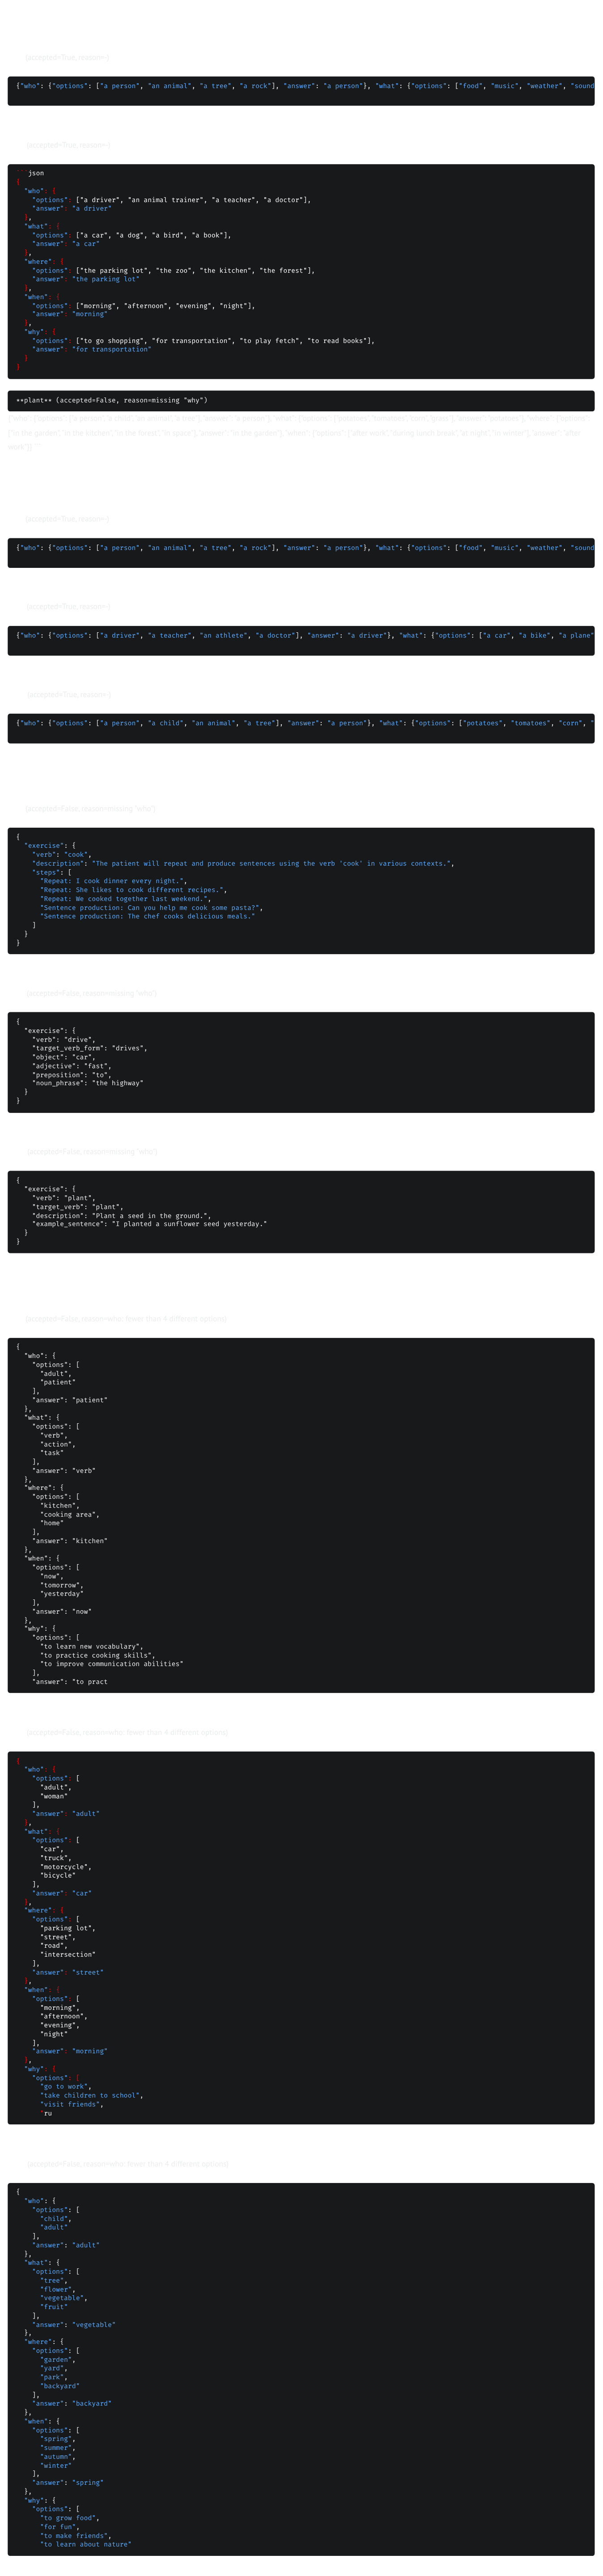

In [ ]:
# A few raw outputs per variant, to read (test split)
_blocks = []
if not ALL.empty:
    for (_p, _d), _sub in ALL[ALL["split"] == "test"].groupby(["prompt_style", "decoding"]):
        _ex = _sub.sort_values("idx").head(3)
        _txt = "\n\n".join(f"**{r.verb}** (accepted={r.accepted}, reason={r.reject_reason or '-'})\n```\n{str(r.output)[:600]}\n```"
                           for r in _ex.itertuples())
        _blocks.append(mo.md(f"#### {_p} prompt, {_d} decoding\n\n{_txt}"))
mo.vstack(_blocks) if _blocks else mo.md("_no outputs yet_")

In [ ]:
# ───────────── finish: outcome tag, close W&B ─────────────
if wb is not None:
    try:
        if not SUMMARY.empty:
            import wandb as _wandb
            wb.log({"summary_table": _wandb.Table(dataframe=SUMMARY)})
        wb.tags = tuple(set(wb.tags) | {"outcome:neutral"})  # a baseline is a reference point, not a success/failure
    except Exception as _e:
        print(f"[wandb] final logging skipped: {str(_e)[:80]}")
    wb.finish()
print("done. Next: copy the test rows of tables/b1__2.01__summary.csv into RESEARCH_LOG §6.1 and add an Experiment Log entry.")

wandb: uploading artifact run-b1-qwen25-1.5b-instruct-untuned-summary_table; updating run metadata
wandb: uploading artifact run-b1-qwen25-1.5b-instruct-untuned-summary_table
wandb: uploading media/table/summary_table_0_a97170bf48ac45aa93e7.table.json
wandb: 
wandb: Run summary:
wandb:      generate-test-long-free/gen_tokens 12161
wandb:       generate-test-long-free/gpu_hours 0.0059
wandb:         generate-test-long-free/n_items 85
wandb: generate-test-long-free/peak_gpu_mem_gb 3.72
wandb:     generate-test-long-free/peak_ram_gb 7.75
wandb:    generate-test-long-free/tokens_per_s 568.2
wandb:     generate-test-long-free/wall_time_h 0.0059
wandb:    generate-test-long-schema/gen_tokens 12901
wandb:     generate-test-long-schema/gpu_hours 0.0062
wandb:       generate-test-long-schema/n_items 85
wandb:                                    +126 ...
wandb: 
wandb: 🚀 View run b1-qwen25-1.5b-instruct-untuned at: https://wandb.ai/team-me-and-me/vnest-exercise-llm/runs/b1-qwen25-1.5b-instruct-un

done. Next: copy the test rows of tables/b1__2.01__summary.csv into RESEARCH_LOG §6.1 and add an Experiment Log entry.
